# BreastDCEDL: exploratory data analysis

What this notebook shows, top to bottom:

- **Part A (metadata, runs anywhere with the repo):**
  - cohorts, labels and splits;
  - missing values;
  - clinical features;
  - imaging parameters and DCE phases;
  - tumour size;
  - how each feature relates to pCR.
- **Part B (images, needs a slice cache):**
  - cache dataset statistics (counts, slices per patient, sizes, intensity ranges);
  - cache quality checks;
  - the three DCE phases of real patients, shown separately and as the RGB image the model sees;
  - enhancement curves.
- **Part C (one patient, from the raw Zenodo arrays to the ViT input; needs a raw `mnj-raw-*` Dataset):**
  1. what the 3D NIfTI arrays look like;
  2. what voxel size and slice thickness mean;
  3. the raw numbers;
  4. the DCE time curve;
  5. intensity normalisation;
  6. RGB reconstruction;
  7. which slices are used;
  8. the 256 → 240 → 224 crops in mm;
  9. the exact tensor given to the ViT.

Where to run it:
- **Kaggle:**
  - attach `mnj-cache-ispy1/-ispy2/-duke` and one raw Dataset (e.g. `mnj-raw-ispy1`, the smallest);
  - add the `GITHUB_TOKEN` secret;
  - CPU is enough.
- **Locally:** Part A always works. Parts B and C run if you copy cache files into `data/cache/<cohort>/` and
  raw files into `data/raw/`.

**Test-set rule:** split *counts* are shown for all splits (they are published). Anything that relates
features or images to the pCR label uses **training patients only**, so we never learn anything from test
labels.

In [1]:
# ==== PARAMETERS ====
GIT_TAG = "d1.4"          # code version to clone on Kaggle (ignored when run inside the repo)
RAW_COHORT = "ispy1"      # Part C: which raw Dataset to read (ispy1 is the smallest)
PID = None                # Part C: a specific training patient, or None = first one found

In [2]:
import glob, json, os, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# repo root: the folder that holds data/metadata (walk up from here), else a Kaggle clone
cands = [Path.cwd(), *Path.cwd().parents, Path("/tmp/repo")]
ROOT = next((p for p in cands if (p / "data" / "metadata").is_dir()), None)
if ROOT is None and os.path.isdir("/kaggle"):     # Kaggle: clone the repo at GIT_TAG with the GITHUB_TOKEN secret
    import base64, subprocess
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("GITHUB_TOKEN")
    _hdr = "Authorization: Basic " + base64.b64encode(f"x-access-token:{_tok}".encode()).decode()
    r = subprocess.run(["git", "-c", f"http.extraHeader={_hdr}", "clone", "--quiet", "--depth", "1", "--branch", GIT_TAG,
                        "https://github.com/AkulaReddy/MRI_chemo_response.git", "/tmp/repo"], capture_output=True, text=True)
    assert r.returncode == 0, (r.stdout + r.stderr).replace(_tok, "***")
    ROOT = Path("/tmp/repo")
assert ROOT is not None, "run this notebook inside the repo (or on Kaggle with the GITHUB_TOKEN secret)"
sys.path.insert(0, str(ROOT))
from src.data.metadata import load_metadata, load_split
from src.data.clinical import race_column

pd.set_option("display.width", 160, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COHORTS = ["ispy1", "ispy2", "duke"]
COLORS = {"ispy1": "#2a6fdb", "ispy2": "#e07b00", "duke": "#1b9e5a"}

meta = load_metadata()                     # checks the CSV md5, adds cohort / split / bbox volume
split = load_split()
df = meta.drop(columns=["split"]).join(split[["split"]])
df["race"] = race_column(df)
df["subtype"] = df["HR_HER2_STATUS"].map({"HRposHER2neg": "HR+/HER2-", "HER2pos": "HER2+", "TripleNeg": "triple-neg"})
lab = df[df.labeled]
train = lab[lab.split == "train"]            # the only labels we analyse
print(f"repo: {ROOT}\n{len(df)} patients, {len(lab)} labeled, {len(train)} labeled train patients")

repo: /tmp/repo
2070 patients, 1452 labeled, 1099 labeled train patients


## A1. Cohorts, labels and splits

- **Labeled** means the patient has a pCR outcome.
- **pCR = 1:** no invasive cancer left at surgery after neoadjuvant chemotherapy.
- Every I-SPY patient is labeled; only 298 of 916 Duke patients are.

In [3]:
t = df.groupby("cohort").agg(patients=("pid", "size"), labeled=("labeled", "sum"),
                             pCR_pos=("pCR", "sum")).loc[COHORTS]
t["pCR_neg"] = t.labeled - t.pCR_pos
t["pCR_rate"] = (t.pCR_pos / t.labeled).round(3)
t.loc["total"] = t.sum(numeric_only=True)
t.loc["total", "pCR_rate"] = round(t.loc["total", "pCR_pos"] / t.loc["total", "labeled"], 3)
display(t.astype({c: int for c in ["patients", "labeled", "pCR_pos", "pCR_neg"]}))

n = pd.crosstab(lab.cohort, lab.split).loc[COHORTS, ["train", "val", "test"]]
p = lab.pivot_table(index="cohort", columns="split", values="pCR", aggfunc="sum").loc[COHORTS, ["train", "val", "test"]].astype(int)
print("labeled patients per split, 'n (pCR+)':")
display(n.astype(str) + " (" + p.astype(str) + ")")
print("unlabeled Duke patients per split (excluded from supervised training and all metrics):")
display(df[~df.labeled].groupby("split").size().rename("unlabeled").to_frame().T)

,patients,labeled,pCR_pos,pCR_neg,pCR_rate
cohort,,,,,
ispy1,172,172,49,123,0.285
ispy2,982,982,316,666,0.322
duke,916,298,63,235,0.211
total,2070,1452,428,1024,0.295


labeled patients per split, 'n (pCR+)':


split,train,val,test
cohort,,,
ispy1,104 (26),33 (11),35 (12)
ispy2,784 (252),99 (32),99 (32)
duke,211 (44),45 (10),42 (9)


unlabeled Duke patients per split (excluded from supervised training and all metrics):


split,test,train,val
unlabeled,94,433,91


## A2. Missing values

How the models handle them (`src/data/clinical.py`, fitted on train only):
- **Categorical features** (HR, HER2, race, menopause) get an extra **"missing"** category.
- **Continuous features** (age, bbox volume) get the **train median** plus a "was missing" flag.

Note that menopause is missing for **every** I-SPY1 patient.

In [4]:
cols = ["pCR", "HR", "HER2", "age", "menopause", "race", "tum_vol", "log_bbox_vol"]
miss = df.groupby("cohort")[cols].apply(lambda g: g.isna().sum()).loc[COHORTS]
miss.loc["total"] = miss.sum()
display(miss)

,pCR,HR,HER2,age,menopause,race,tum_vol,log_bbox_vol
cohort,,,,,,,,
ispy1,0,2,5,0,172,0,0,0
ispy2,0,0,0,3,38,3,0,0
duke,618,0,0,0,0,0,3,0
total,618,2,5,3,210,3,3,0


## A3. Clinical features by cohort (all labeled patients)

- **HR+:** the tumour has oestrogen and/or progesterone receptors.
- **HER2+:** the tumour over-expresses HER2.
- **Subtype:** HR+/HER2−, HER2+ (any HR), or triple-negative.
- The receptor thresholds differ by cohort:
  - HR+: ≥1% stained cells in I-SPY2, ≥10% in I-SPY1, Allred >3 in Duke;
  - HER2+: FISH ratio ≥2.0 in I-SPY, >2.2 in Duke.

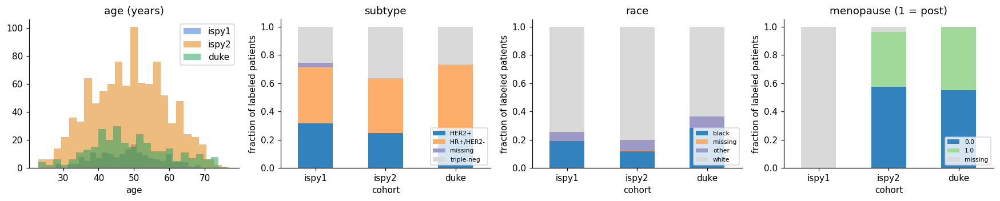

,age,HR+ rate,HER2+ rate
cohort,,,
ispy1,48.02,0.56,0.32
ispy2,48.75,0.55,0.25
duke,49.19,0.64,0.27


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3))
for c in COHORTS:
    axes[0].hist(lab[lab.cohort == c].age.dropna(), bins=25, alpha=0.5, color=COLORS[c], label=c)
axes[0].set(title="age (years)", xlabel="age"); axes[0].legend()
for ax, col, title in [(axes[1], "subtype", "subtype"), (axes[2], "race", "race"), (axes[3], "menopause", "menopause (1 = post)")]:
    ct = pd.crosstab(lab.cohort, lab[col].fillna("missing").astype(str), normalize="index").loc[COHORTS]
    ct.plot.bar(stacked=True, ax=ax, rot=0, colormap="tab20c", legend=True)
    ax.set(title=title, ylabel="fraction of labeled patients"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()
display(lab.groupby("cohort")[["age", "HR", "HER2"]].mean().loc[COHORTS].round(2).rename(columns={"HR": "HR+ rate", "HER2": "HER2+ rate"}))

## A4. Imaging parameters and DCE phases

- **`n_xy`:** in-plane size of the *original* scan. The archive volumes are 256×256 windows of it, which is
  why the metadata tumour boxes had to be shifted (`challenges.md`).
- **`n_z`:** number of slices.
- **`slice_thick` / `xy_spacing`:** mm between slices and mm per pixel.
- **`n_times`:** number of DCE acquisitions.
- **`pre` / `post_early` / `post_late`:** which acquisition is used for the R, G and B channels.

n_xy: {'ispy1': {256.0: 157, 512.0: 15}, 'ispy2': {128.0: 2, 256.0: 767, 312.0: 19, 320.0: 53, 384.0: 140, 448.0: 1}, 'duke': {256.0: 914, 448.0: 2}}
n_times: {'ispy1': {3.0: 135, 4.0: 21, 5.0: 1, 6.0: 15}, 'ispy2': {4.0: 1, 5.0: 8, 6.0: 181, 7.0: 471, 8.0: 280, 9.0: 39, 10.0: 1, 11.0: 1}, 'duke': {3.0: 3, 4.0: 480, 5.0: 433}}
pre: {'ispy1': {0.0: 172}, 'ispy2': {0.0: 982}, 'duke': {0.0: 916}}
post_early: {'ispy1': {1.0: 140, 2.0: 32}, 'ispy2': {1.0: 1, 2.0: 980, 3.0: 1}, 'duke': {1.0: 916}}
post_late: {'ispy1': {2.0: 141, 3.0: 17, 5.0: 14}, 'ispy2': {3.0: 1, 4.0: 10, 5.0: 494, 6.0: 476, 7.0: 1}, 'duke': {2.0: 3, 3.0: 480, 4.0: 433}}


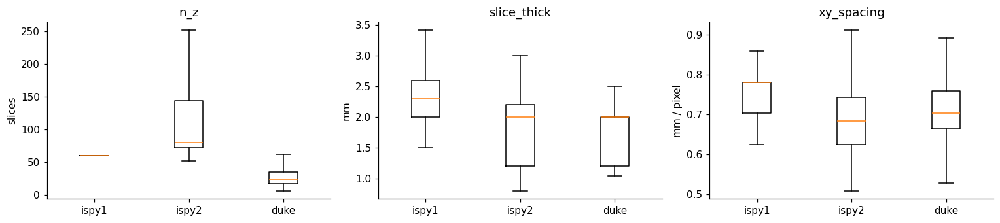

In [6]:
for col in ["n_xy", "n_times", "pre", "post_early", "post_late"]:
    print(f"{col}:", {c: df[df.cohort == c][col].value_counts().sort_index().astype(int).to_dict() for c in COHORTS})
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, col, unit in zip(axes, ["n_z", "slice_thick", "xy_spacing"], ["slices", "mm", "mm / pixel"]):
    ax.boxplot([df[df.cohort == c][col].dropna() for c in COHORTS], showfliers=False)
    ax.set_xticks([1, 2, 3], COHORTS); ax.set(title=col, ylabel=unit)
plt.tight_layout(); plt.show()

## A5. Tumour size

- **bbox volume** = (slices spanned × slice thickness) × (rows × pixel size) × (columns × pixel size), in mm³,
  from the metadata box.
- We use its **log** because the raw volume is very skewed.
- `tum_vol` is the dataset's own tumour volume, from the mask voxel count in I-SPY. For I-SPY you can see how
  well the bbox volume tracks it.

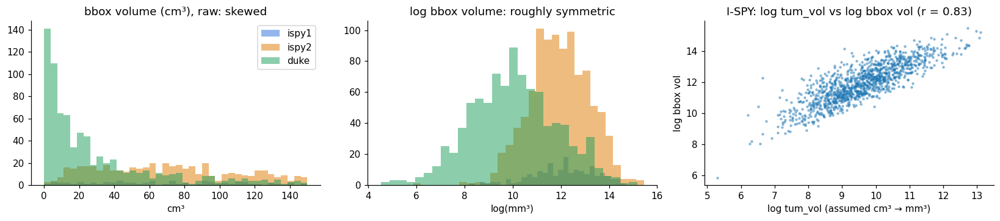

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for c in COHORTS:
    d = df[df.cohort == c]
    axes[0].hist(d.bbox_vol_mm3 / 1000, bins=40, range=(0, 150), alpha=0.5, color=COLORS[c], label=c)
    axes[1].hist(d.log_bbox_vol, bins=30, alpha=0.5, color=COLORS[c], label=c)
axes[0].set(title="bbox volume (cm³), raw: skewed", xlabel="cm³"); axes[0].legend()
axes[1].set(title="log bbox volume: roughly symmetric", xlabel="log(mm³)")
isp = df[df.cohort != "duke"].dropna(subset=["tum_vol"])
axes[2].scatter(np.log(isp.tum_vol * 1000), isp.log_bbox_vol, s=4, alpha=0.4)
r = np.corrcoef(np.log(isp.tum_vol * 1000), isp.log_bbox_vol)[0, 1]
axes[2].set(title=f"I-SPY: log tum_vol vs log bbox vol (r = {r:.2f})", xlabel="log tum_vol (assumed cm³ → mm³)", ylabel="log bbox vol")
plt.tight_layout(); plt.show()

## A6. What predicts pCR? (training patients only)

- **pCR rate by subtype and cohort:** expect HR+/HER2− lowest and HER2+ / triple-negative highest.
- **Univariate AUC:** each feature's AUC on its own; 0.5 = no signal.
  - Values below 0.5 mean that **higher values go with less pCR** (e.g. larger tumours).
  - The table also shows `max(AUC, 1 − AUC)`, the signal strength regardless of direction.

mean             size            
cohort      duke ispy1 ispy2 duke ispy1 ispy2
subtype                                      
HER2+       0.31  0.44  0.46   58    32   198
HR+/HER2-   0.08  0.07  0.17  107    42   305
triple-neg  0.37  0.30  0.39   46    27   281

cohort,all,ispy1,ispy2,duke
feature,,,,
HER2,0.585,0.662,0.580,0.585
HR,0.366,0.280,0.385,0.347
age,0.458,0.466,0.476,0.371
log_bbox_vol,0.446,0.468,0.408,0.493
menopause,0.478,NaN,0.500,0.385
race_black,0.484,0.423,0.497,0.499


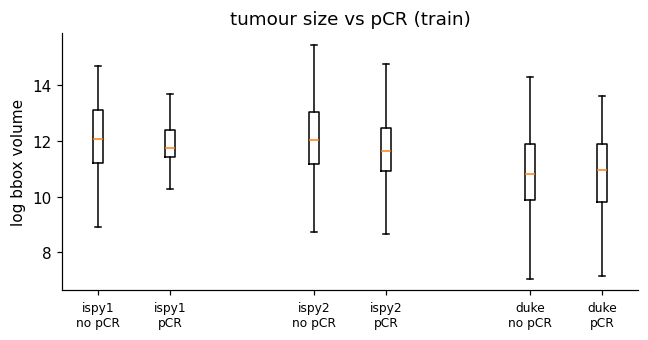

In [8]:
rate = train.pivot_table(index="subtype", columns="cohort", values="pCR", aggfunc=["mean", "size"])
display(rate.round(2))

rows = []
feats = {"HR": train.HR, "HER2": train.HER2, "age": train.age, "menopause": train.menopause,
         "race_black": (train.race == "black").astype(float).where(train.race.notna()),
         "log_bbox_vol": train.log_bbox_vol}
for name, x in feats.items():
    for c in ["all", *COHORTS]:
        m = (train.cohort == c) if c != "all" else pd.Series(True, index=train.index)
        ok = m & x.notna()
        y = train.pCR[ok]
        if y.nunique() == 2 and x[ok].nunique() > 1:
            a = roc_auc_score(y, x[ok])
            rows.append({"feature": name, "cohort": c, "n": int(ok.sum()), "AUC": round(a, 3), "strength": round(max(a, 1 - a), 3)})
uni = pd.DataFrame(rows).pivot(index="feature", columns="cohort", values="AUC")[["all", *COHORTS]]
display(uni)

fig, ax = plt.subplots(figsize=(6, 3.2))
for i, c in enumerate(COHORTS):
    d = train[train.cohort == c]
    ax.boxplot([d[d.pCR == 0].log_bbox_vol, d[d.pCR == 1].log_bbox_vol], positions=[3 * i, 3 * i + 1], showfliers=False)
ax.set_xticks([0, 1, 3, 4, 6, 7], [f"{c}\n{t}" for c in COHORTS for t in ("no pCR", "pCR")], fontsize=8)
ax.set(title="tumour size vs pCR (train)", ylabel="log bbox volume"); plt.tight_layout(); plt.show()

### What Part A means for modelling

- **Class imbalance:** about 30% pCR+, so AUPRC's chance level is about 0.30, not 0.5. That's also why the
  neural models use focal loss.
- **The clinical signal is concentrated in HR and HER2** (subtype). That's why the clinical-only baseline B1
  is a hard bar.
- **Cohorts differ** in pCR rate, receptor definitions, slice thickness and missingness. Report results per
  cohort, and watch for "cohort shortcuts": for example, `menopause = missing` ≈ I-SPY1.
- **Duke's 618 unlabeled patients** are only usable for self-supervised pretraining (train + val only).

# Part B: images (needs a slice cache)

Each cache file `<pid>.npz` holds:
- `rgb`: (slices, 240, 240, 3) uint8, R/G/B = pre/early/late, jointly clipped at the 0.5–99.5 percentiles;
- `t0:t1`: the tumour slices;
- `bbox`: the tumour box inside the crop;
- `mask`: the tumour mask, I-SPY only.

The model sees a 224×224 crop of this, normalised with ImageNet mean and std.

In [9]:
roots = [Path(os.environ["EDA_CACHE_ROOT"])] if os.environ.get("EDA_CACHE_ROOT") else []
roots += [ROOT / "data" / "cache", Path("/kaggle/input"), Path("/kaggle/working")]
CACHES = {}
for r in roots:
    for depth in range(6):
        for f in glob.glob(os.path.join(r, *["*"] * depth, "cache_meta.json")):
            CACHES.setdefault(json.load(open(f))["cohort"], Path(f).parent)
HAVE_CACHE = bool(CACHES)
print("caches found:", {c: str(p) for c, p in CACHES.items()} or "none -> Part B skipped")

caches found: {'ispy2': '/kaggle/input/datasets/akulareddy/mnj-cache-ispy2/cache_ispy2', 'ispy1': '/kaggle/input/datasets/akulareddy/mnj-cache-ispy1/cache_ispy1', 'duke': '/kaggle/input/datasets/avreddy0007/mnj-cache-duke/cache_duke'}


## B0. The cache datasets in numbers

The cache has one row per patient in `cache_index.csv`, which we join with the metadata. The tables show:
- **counts:** patients cached, ok / error, labeled, and per split;
- **per-patient statistics** (mean, median, min, max):
  - `depth`: slices in the archive volume;
  - `n_slices`: slices kept in the cache (tumour ± 2);
  - `tumour slices`: `t1 − t0`, what the model samples from;
  - tumour extent in mm (slices × slice thickness, box height and width × pixel size);
  - the intensity clip range `clip_lo` / `clip_hi` (raw scanner units, so very different between cohorts);
  - the mean RGB value inside the tumour slices;
  - file size;
- **distributions** of tumour slices per patient and of the 224-px field of view in mm.

patients in each cache:


,patients,ok,error,ok_labeled,ok_labeled_train,ok_labeled_val,ok_labeled_test,total_MB
cohort,,,,,,,,
duke,920,914,6,297,210,45,42,3056
ispy1,172,172,0,172,104,33,35,593
ispy2,1139,982,157,982,784,99,99,4791


per-patient statistics of the ok rows (rows = column / statistic, columns = cohort):


cohort                  duke     ispy1     ispy2
depth         mean      29.3      30.0      42.5
              median    24.0      29.0      38.0
              min        6.0      10.0       5.0
              max      135.0      72.0     150.0
n_slices      mean      28.3      30.0      42.5
              median    23.0      29.0      38.0
              min        5.0      10.0       5.0
              max      134.0      72.0     150.0
tumour_slices mean      24.3      26.1      38.5
              median    19.0      25.0      34.0
              min        1.0       6.0       1.0
              max      130.0      68.0     149.0
tumour_z_mm   mean      42.0      63.8      61.0
              median    32.4      57.8      54.0
              min        2.0      15.0       2.2
              max      236.0     208.0     178.8
box_h_mm      mean      34.6      60.5      63.8
              median    27.2      52.9      59.4
              min        5.3      16.4      13.3
              max      156.3     128.0     170.6
box_w_mm      mean      29.3      63.8      53.4
              median    25.2      60.2      47.5
              min        4.0      14.8      10.3
              max      140.0     150.9     184.4
fov224_mm     mean     161.3     169.0     160.2
              median   157.5     175.0     153.1
              min      113.7      87.5      70.0
              max      280.0     262.5     315.0
clip_lo       mean       0.8       1.5       0.2
              median     0.0       0.0       0.0
              min        0.0       0.0       0.0
              max       17.0      10.0       6.0
clip_hi       mean    1931.7     246.6    1290.0
              median  1704.0     156.0    1031.0
              min      108.0      56.0      90.0
              max     7109.0    2367.0    5597.0
tumor_mean    mean      39.0      43.4      40.9
              median    38.1      39.7      39.6
              min       17.3      20.4      18.4
              max       84.6     124.8     105.3
mask_vox      mean       NaN   24861.5   36143.8
              median     NaN   14516.5   18029.0
              min        NaN     361.0     185.0
              max        NaN  276668.0  805224.0
file_mb       mean       3.3       3.4       4.9
              median     2.7       3.2       4.4
              min        0.6       1.0       0.6
              max       15.1       8.8      16.7

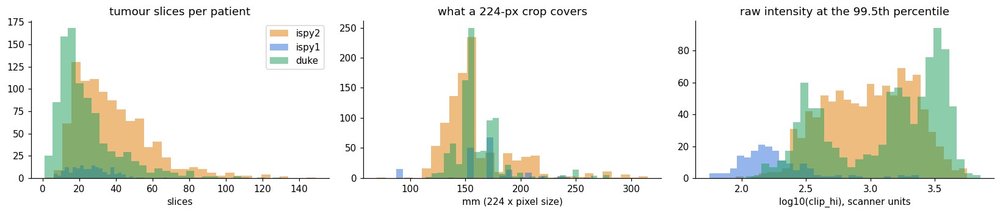

In [10]:
if HAVE_CACHE:
    allidx = []
    for c, d in CACHES.items():
        idx = pd.read_csv(d / "cache_index.csv")
        idx["cohort"] = c
        idx["file_mb"] = [os.path.getsize(d / f"{p}.npz") / 1e6 if (d / f"{p}.npz").exists() else np.nan for p in idx.pid]
        allidx.append(idx)
    ci = pd.concat(allidx, ignore_index=True)
    ci = ci.join(df[["split", "labeled", "slice_thick", "xy_spacing", "sraw", "eraw", "scol", "ecol"]], on="pid")
    ok = ci[ci.status == "ok"].copy()

    counts = ci.groupby("cohort").agg(patients=("pid", "size"), ok=("status", lambda s: (s == "ok").sum()),
                                      error=("status", lambda s: (s != "ok").sum()))
    counts["ok_labeled"] = ok[ok.labeled == True].groupby("cohort").size()
    for sp in ["train", "val", "test"]:
        counts[f"ok_labeled_{sp}"] = ok[(ok.labeled == True) & (ok.split == sp)].groupby("cohort").size()
    counts["total_MB"] = ci.groupby("cohort").file_mb.sum().round(0)
    print("patients in each cache:")
    display(counts.fillna(0).astype(int))

    if {"t0", "t1"} <= set(ok.columns):
        ok["tumour_slices"] = ok.t1 - ok.t0
        ok["tumour_z_mm"] = ok.tumour_slices * ok.slice_thick
    ok["box_h_mm"] = (ok.eraw - ok.sraw) * ok.xy_spacing          # CSV box is in original pixels (true size)
    ok["box_w_mm"] = (ok.ecol - ok.scol) * ok.xy_spacing
    ok["fov224_mm"] = 224 * ok.xy_spacing
    cols = [c for c in ["depth", "n_slices", "tumour_slices", "tumour_z_mm", "box_h_mm", "box_w_mm", "fov224_mm",
                        "clip_lo", "clip_hi", "tumor_mean", "mask_vox", "file_mb"] if c in ok]
    stats = ok.groupby("cohort")[cols].agg(["mean", "median", "min", "max"]).T.round(1)
    print("per-patient statistics of the ok rows (rows = column / statistic, columns = cohort):")
    display(stats)

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.3))
    for c in CACHES:
        o = ok[ok.cohort == c]
        if "tumour_slices" in o:
            axes[0].hist(o.tumour_slices, bins=30, alpha=0.5, color=COLORS.get(c), label=c)
        axes[1].hist(o.fov224_mm, bins=30, alpha=0.5, color=COLORS.get(c), label=c)
        if "clip_hi" in o:
            axes[2].hist(np.log10(o.clip_hi.clip(lower=1)), bins=30, alpha=0.5, color=COLORS.get(c), label=c)
    axes[0].set(title="tumour slices per patient", xlabel="slices"); axes[0].legend()
    axes[1].set(title="what a 224-px crop covers", xlabel="mm (224 x pixel size)")
    axes[2].set(title="raw intensity at the 99.5th percentile", xlabel="log10(clip_hi), scanner units")
    plt.tight_layout(); plt.show()

## B1. Cache quality checks

In [11]:
if HAVE_CACHE:
    for c, d in CACHES.items():
        idx = pd.read_csv(d / "cache_index.csv")
        print(f"\n== {c}: {len(idx)} patients")
        for col in ["status", "z_source", "xy_source"]:
            if col in idx:
                print(f"  {col}:", idx[col].value_counts(dropna=False).to_dict())
        ok = idx[idx.status == "ok"]
        if {"t0", "t1"} <= set(ok.columns):
            print("  tumour slices per patient:", ok.eval("t1 - t0").describe()[["min", "50%", "max"]].to_dict())
        if "mask_csv_iou_yx" in ok:
            iou = ok.mask_csv_iou_yx.dropna()
            if len(iou):
                print("  CSV box vs mask IoU: min %.2f, median %.2f" % (iou.min(), iou.median()))
        err = idx[idx.status != "ok"]
        if len(err):
            display(err[[c for c in ["pid", "status", "note"] if c in err]].head(10))


== ispy2: 1139 patients
  status: {'ok': 982, 'not_in_metadata': 157}
  z_source: {'mask': 980, nan: 157, 'csv': 2}
  xy_source: {'csv': 767, 'mask': 215, nan: 157}
  tumour slices per patient: {'min': 1.0, '50%': 34.0, 'max': 149.0}
  CSV box vs mask IoU: min 0.91, median 1.00


,pid,status,note
0,ISPY1_1001,not_in_metadata,NaN
1,ISPY1_1002,not_in_metadata,NaN
2,ISPY1_1003,not_in_metadata,NaN
3,ISPY1_1004,not_in_metadata,NaN
4,ISPY1_1005,not_in_metadata,NaN
5,ISPY1_1007,not_in_metadata,NaN
6,ISPY1_1008,not_in_metadata,NaN
7,ISPY1_1009,not_in_metadata,NaN
8,ISPY1_1010,not_in_metadata,NaN
9,ISPY1_1011,not_in_metadata,NaN



== ispy1: 172 patients
  status: {'ok': 172}
  z_source: {'mask': 172}
  xy_source: {'csv': 157, 'mask': 15}
  tumour slices per patient: {'min': 6.0, '50%': 25.0, 'max': 68.0}
  CSV box vs mask IoU: min 0.11, median 1.00

== duke: 920 patients
  status: {'ok': 914, 'not_in_metadata': 4, 'error': 2}
  z_source: {'csv': 914, nan: 6}
  xy_source: {'csv': 914, nan: 4, 'csv_shifted': 2}
  tumour slices per patient: {'min': 1.0, '50%': 19.0, 'max': 130.0}


,pid,status,note
0,Breast_MRI_700,not_in_metadata,NaN
1,Breast_MRI_728,not_in_metadata,NaN
2,Breast_MRI_801,not_in_metadata,NaN
3,Breast_MRI_893,not_in_metadata,NaN
147,Breast_MRI_577,error,in-plane 256x256 != n_xy 448; ValueError: dept...
155,Breast_MRI_250,error,in-plane 256x256 != n_xy 448; ValueError: dept...


## B2. One patient, phase by phase

For a few **training** patients (pCR+ and pCR−) we show, from the middle tumour slice:
- each DCE phase on its own (grey);
- the RGB composite;
- the tumour box (yellow) and, for I-SPY, the mask outline (cyan).

The tumour should be **dark in pre, bright in early**, and then either fade (washout) or stay bright in late.

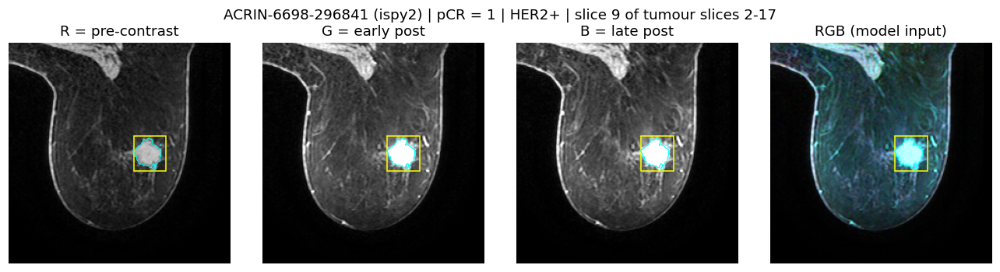

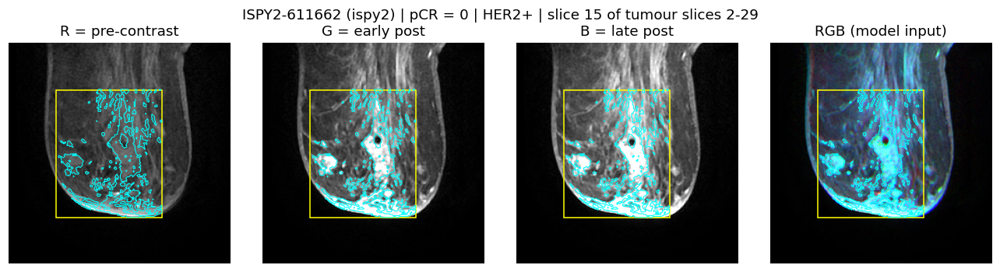

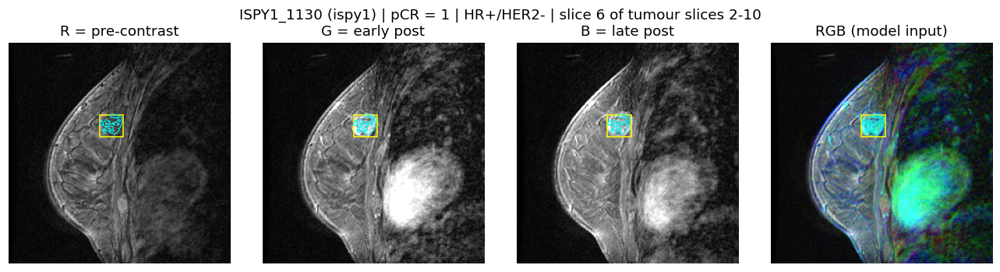

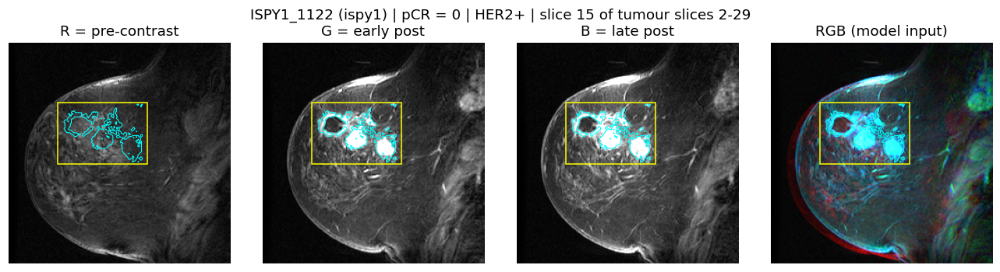

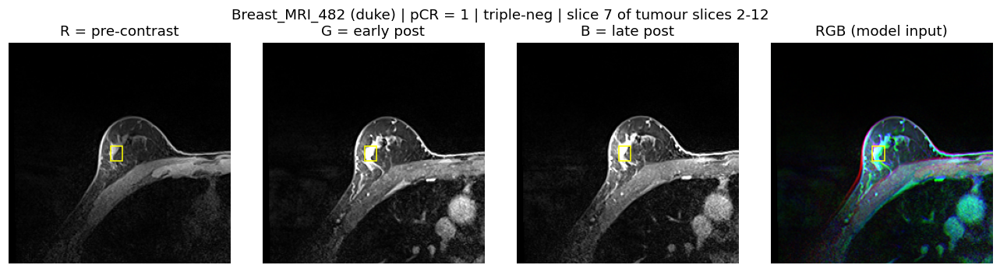

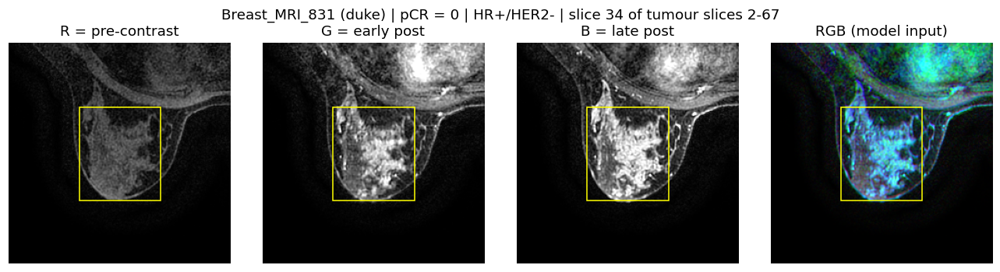

In [12]:
def load(pid, cohort):
    p = CACHES[cohort] / f"{pid}.npz"
    return np.load(p) if p.exists() else None

def show_patient(pid, cohort):
    d = load(pid, cohort)
    if d is None:
        return False
    k = (int(d["t0"]) + int(d["t1"])) // 2
    img = d["rgb"][k]
    y0, y1, x0, x1 = d["bbox"]
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
    for i, name in enumerate(["R = pre-contrast", "G = early post", "B = late post"]):
        axes[i].imshow(img[..., i], cmap="gray", vmin=0, vmax=255); axes[i].set_title(name)
    axes[3].imshow(img); axes[3].set_title("RGB (model input)")
    for ax in axes:
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="yellow", lw=1))
        if "mask" in d and d["mask"][k].any():
            ax.contour(d["mask"][k], levels=[0.5], colors="cyan", linewidths=0.7)
        ax.axis("off")
    lab_ = int(train.loc[pid, "pCR"])
    fig.suptitle(f"{pid} ({cohort}) | pCR = {lab_} | {train.loc[pid, 'subtype']} | slice {k} of tumour slices {int(d['t0'])}-{int(d['t1'])}")
    plt.tight_layout(); plt.show()
    return True

if HAVE_CACHE:
    rng = np.random.default_rng(0)
    for c in CACHES:
        avail = {Path(f).stem for f in glob.glob(str(CACHES[c] / "*.npz"))}
        for y in (1, 0):
            pids = [p for p in train[(train.cohort == c) & (train.pCR == y)].pid if p in avail]
            for pid in rng.permutation(pids)[:1]:
                show_patient(pid, c)

## B3. Enhancement curves: does the image carry pCR signal?

- For up to 150 training patients per cohort, take the mean intensity of each phase inside the tumour (the
  mask for I-SPY, the box for Duke).
- Then compare pCR+ with pCR− patients, as **enhancement relative to pre-contrast**.
- Overlapping curves mean the simple kinetics differ little between responders and non-responders. Any image
  model then has to find subtler patterns: texture, shape, heterogeneity.

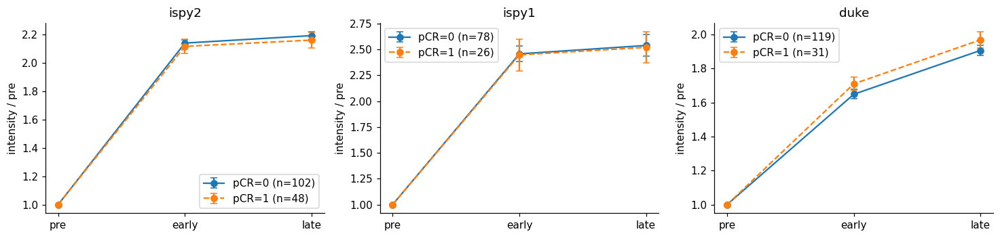

In [13]:
if HAVE_CACHE:
    fig, axes = plt.subplots(1, len(CACHES), figsize=(4.5 * len(CACHES), 3.3), squeeze=False)
    for ax, c in zip(axes[0], CACHES):
        avail = {Path(f).stem for f in glob.glob(str(CACHES[c] / "*.npz"))}
        sub = train[(train.cohort == c) & train.pid.isin(avail)]
        sub = sub.sample(min(150, len(sub)), random_state=0)
        curves = {0: [], 1: []}
        for pid, y in zip(sub.pid, sub.pCR.astype(int)):
            d = load(pid, c)
            t0, t1 = int(d["t0"]), int(d["t1"])
            vol = d["rgb"][t0:t1].astype(float)
            if "mask" in d and d["mask"][t0:t1].any():
                sel = d["mask"][t0:t1] > 0
            else:
                y0, y1, x0, x1 = d["bbox"]
                sel = np.zeros(vol.shape[:3], bool); sel[:, y0:y1, x0:x1] = True
            m = vol[sel].mean(axis=0)            # mean R, G, B inside the tumour
            curves[y].append(m / max(m[0], 1.0))  # relative to pre-contrast
        for y, style in [(0, "-"), (1, "--")]:
            a = np.array(curves[y])
            if len(a):
                ax.errorbar([0, 1, 2], a.mean(0), yerr=a.std(0) / np.sqrt(len(a)), ls=style, marker="o", capsize=3,
                            label=f"pCR={y} (n={len(a)})")
        ax.set(xticks=[0, 1, 2], xticklabels=["pre", "early", "late"], title=c, ylabel="intensity / pre")
        ax.legend()
    plt.tight_layout(); plt.show()

## B4. What the model actually receives

- The centre 224×224 crop of three tumour slices, as the model sees them: after cropping, before ImageNet
  normalisation.
- During training it also gets random flips, ±15° rotation, 0.9–1.1 scaling, ±10% intensity and ±8 px
  shifts.
- Check that the tumour (yellow box) is inside the crop and the colours look the same as in B2.

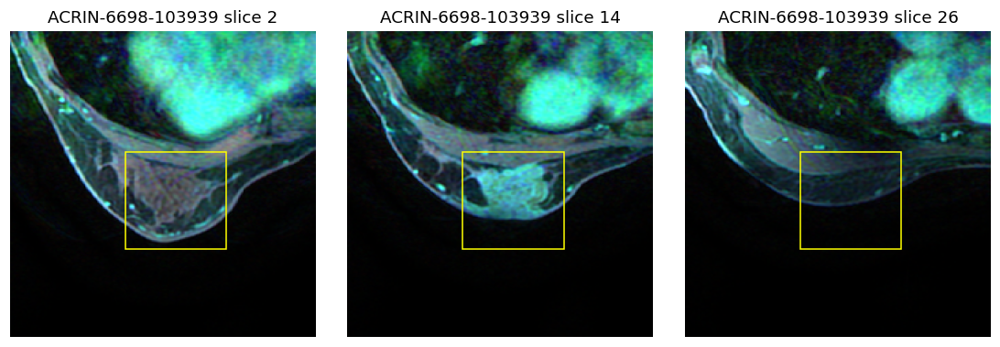

In [14]:
if HAVE_CACHE:
    c = next(iter(CACHES))
    avail = sorted(Path(f).stem for f in glob.glob(str(CACHES[c] / "*.npz")))
    pid = next(p for p in avail if p in train.index)
    d = load(pid, c)
    t0, t1 = int(d["t0"]), int(d["t1"])
    ks = np.unique(np.linspace(t0, t1 - 1, 3).round().astype(int))
    off = (240 - 224) // 2
    y0, y1, x0, x1 = d["bbox"] - off
    fig, axes = plt.subplots(1, len(ks), figsize=(3.4 * len(ks), 3.4), squeeze=False)
    for ax, k in zip(axes[0], ks):
        ax.imshow(d["rgb"][k, off:off + 224, off:off + 224])
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="yellow", lw=1))
        ax.set_title(f"{pid} slice {k}"); ax.axis("off")
    plt.tight_layout(); plt.show()

# Part C: one patient, from the Zenodo arrays to the ViT input

We read one training patient's raw files, then **run the real cache builder on them**
(`process()` from `scripts/build_cache.py`), so every picture below shows exactly what the pipeline does.

Steps:
- **C1:** the raw files and arrays;
- **C2:** a 3D volume as a stack of slices, and what slice thickness means;
- **C3:** the raw numbers;
- **C4:** the DCE time curve and the three phases we pick;
- **C5:** intensity normalisation to uint8;
- **C6:** rebuilding the RGB image;
- **C7:** which slices are used;
- **C8:** the 256 → 240 → 224 crops, in mm;
- **C9:** the exact tensor given to the ViT.

In [15]:
import importlib.util, subprocess, tarfile, tempfile
from collections import defaultdict
try:
    import nibabel as nib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nibabel"], check=True)
    import nibabel as nib
from src.data.metadata import COHORTS as DS_CODE, parse_name
from src.data.nifti_io import _from_bytes, load_volume
from src.data.rgb_slices import CACHE_SIZE, INPUT_SIZE, to_rgb_uint8

spec = importlib.util.spec_from_file_location("build_cache", ROOT / "scripts" / "build_cache.py")
bc = importlib.util.module_from_spec(spec); spec.loader.exec_module(bc)

prefix = f"BreastDCEDL_{RAW_COHORT.upper()}_min_crop"
raw_roots = [Path(os.environ["EDA_RAW_ROOT"])] if os.environ.get("EDA_RAW_ROOT") else []
raw_roots += [ROOT / "data" / "raw", Path("/kaggle/input")]
RAW = None
for r in raw_roots:
    for depth in range(6):
        hits = sorted(glob.glob(os.path.join(str(r), *["*"] * depth, prefix + "*")))
        if hits:
            RAW = Path(hits[0]); break
    if RAW:
        break
HAVE_RAW = RAW is not None
print("raw data:", RAW if HAVE_RAW else f"no '{prefix}*' folder or tarball found -> Part C skipped")

def raw_patient(raw, cohort, pid=None):
    # -> (pid, {acquisition k or 'mask': path or bytes}) for one labeled training patient
    ds = DS_CODE[cohort]
    want = {pid} if pid else set(train[train.cohort == cohort].pid)
    files = defaultdict(dict)
    tars = [raw] if raw.is_file() else sorted(raw.rglob("*.tar.gz"))
    if not tars:                                            # extracted archive (Kaggle unpacks .tar.gz)
        for p in sorted(raw.rglob("*.nii*")):
            q = parse_name(p.name)
            if q and q[2] == ds and q[1] in want:
                files[q[1]]["mask" if q[0] == "mask" else q[3]] = p
        chosen = pid or sorted(files)[0]
        return chosen, files[chosen]
    chosen = pid
    for t in tars:                                          # stream the tarball until one patient is complete
        with tarfile.open(t, "r|gz") as tf:
            for m in tf:
                q = parse_name(m.name) if m.isfile() else None
                if not q or q[2] != ds or q[1] not in want or (chosen and q[1] != chosen):
                    continue
                chosen = q[1]
                files[chosen]["mask" if q[0] == "mask" else q[3]] = tf.extractfile(m).read()
                need = int(df.loc[chosen, "n_times"]) + (cohort != "duke")
                if len(files[chosen]) >= need:
                    return chosen, files[chosen]
    return chosen, files[chosen]

if HAVE_RAW:
    PID_, FILES = raw_patient(RAW, RAW_COHORT, PID)
    row = df.loc[PID_]
    ACQ = sorted(k for k in FILES if k != "mask")
    USED, note = bc.resolve_phases(row, ACQ)
    VOLS = {k: load_volume(FILES[k]) for k in ACQ}                 # float32 (Z, H, W)
    MASK = load_volume(FILES["mask"], np.uint8) if "mask" in FILES else None
    r = {**row.to_dict(), "phases_used": USED}
    tmp = Path(tempfile.mkdtemp())
    QC = bc.process(PID_, r, {k: FILES[k] for k in USED}, FILES.get("mask"), tmp)   # the real cache builder
    assert QC["status"] == "ok", QC
    CACHE = dict(np.load(tmp / f"{PID_}.npz"))
    cy0, cx0 = CACHE["crop_origin"]
    Z0, Z1 = int(QC["z0"]), int(QC["z1"])
    BY0, BY1, BX0, BX1 = (CACHE["bbox"] + [cy0, cy0, cx0, cx0]).tolist()   # tumour box in the 256 image
    ZM, YC, XC = (Z0 + Z1) // 2, (BY0 + BY1) // 2, (BX0 + BX1) // 2
    XY, TH = float(row.xy_spacing), float(row.slice_thick)
    print(f"patient {PID_} ({RAW_COHORT}), pCR = {int(row.pCR)}, {row.subtype}; acquisitions on disk: {ACQ}; "
          f"used (pre, early, late) = {USED} {note}")

raw data: /kaggle/input/datasets/akulareddy/mnj-raw-ispy/BreastDCEDL_ISPY1_min_crop
patient ISPY1_1001 (ispy1), pCR = 0, HR+/HER2-; acquisitions on disk: [0, 1, 2]; used (pre, early, late) = [0, 1, 2] 


## C1. The raw files and arrays

- Each DCE acquisition is a **separate NIfTI file**, holding one 3D array (slices, rows, columns).
- Look at:
  - the shapes;
  - the data type on disk (float64: raw scanner values, never normalised);
  - the **header spacing**, which says 1 mm and is wrong;
  - the true spacing from the CSV.

In [16]:
if HAVE_RAW:
    rows_ = []
    for k in [*ACQ, *(["mask"] if MASK is not None else [])]:
        src = FILES[k]
        img = _from_bytes(src) if isinstance(src, (bytes, bytearray)) else nib.load(str(src))
        a = MASK if k == "mask" else VOLS[k]
        role = {USED[0]: "pre (R)", USED[1]: "early (G)", USED[2]: "late (B)"}.get(k, "not used") if k != "mask" else "tumour mask"
        rows_.append({"file": f"acquisition {k}" if k != "mask" else "mask", "role": role, "shape (Z, H, W)": a.shape,
                      "dtype on disk": str(img.header.get_data_dtype()), "header spacing": tuple(round(float(z), 2) for z in img.header.get_zooms()),
                      "min": float(a.min()), "mean": round(float(a.mean()), 1), "max": float(a.max())})
    display(pd.DataFrame(rows_))
    Zd, H, W = VOLS[USED[0]].shape
    print(f"true spacing (CSV): pixel {XY:.3f} x {XY:.3f} mm, slice thickness {TH:.2f} mm "
          f"-> one voxel = {XY:.2f} x {XY:.2f} x {TH:.2f} mm = {XY * XY * TH:.2f} mm3")
    print(f"the whole array covers {W * XY:.0f} mm x {H * XY:.0f} mm in-plane and {Zd * TH:.0f} mm across {Zd} slices")
    print(f"original scan size n_xy = {int(row.n_xy)} px; tumour box (CSV, original pixels): rows {int(row.sraw)}-{int(row.eraw)}, "
          f"cols {int(row.scol)}-{int(row.ecol)}, slices {int(row.mask_start)}-{int(row.mask_end)}")
    print(f"builder QC: z from {QC['z_source']}, box from {QC['xy_source']}, tumour slices {Z0}-{Z1}, "
          f"tumour box in this array: rows {BY0}-{BY1}, cols {BX0}-{BX1}")

,file,role,"shape (Z, H, W)",dtype on disk,header spacing,min,mean,max
0,acquisition 0,pre (R),"(30, 256, 256)",float64,"(1.0, 1.0, 1.0)",0.0,13.2,138.0
1,acquisition 1,early (G),"(30, 256, 256)",float64,"(1.0, 1.0, 1.0)",0.0,16.4,211.0
2,acquisition 2,late (B),"(30, 256, 256)",float64,"(1.0, 1.0, 1.0)",0.0,17.8,224.0
3,mask,tumour mask,"(30, 256, 256)",float64,"(1.0, 1.0, 1.0)",0.0,0.0,1.0


true spacing (CSV): pixel 0.781 x 0.781 mm, slice thickness 2.00 mm -> one voxel = 0.78 x 0.78 x 2.00 mm = 1.22 mm3
the whole array covers 200 mm x 200 mm in-plane and 60 mm across 30 slices
original scan size n_xy = 256 px; tumour box (CSV, original pixels): rows 110-192, cols 59-144, slices 12-38
builder QC: z from mask, box from csv, tumour slices 2-28, tumour box in this array: rows 110-192, cols 59-144


## C2. A 3D volume is a stack of 2D slices, and slices have a thickness

- The array is a pile of 2D images.
- Each slice is **one 2D image of a thin slab of tissue, `slice_thick` mm thick**. Each pixel stands for a
  small box (a **voxel**):
  - pixel size × pixel size in-plane, e.g. 0.7 × 0.7 mm;
  - by the slice thickness in depth, e.g. 2 mm.
- So voxels are usually **longer in depth than wide** ("anisotropic").
- The bottom row cuts the volume *across* the slices, through the tumour centre:
  - **left:** drawn one pixel per slice, which squashes the depth direction;
  - **right:** drawn at true physical proportions, so each slice becomes a band `slice_thick` mm tall.
- The red lines mark the tumour slices.

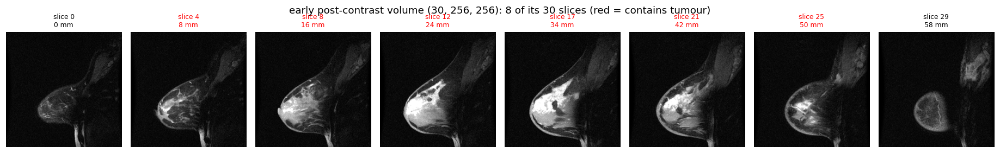

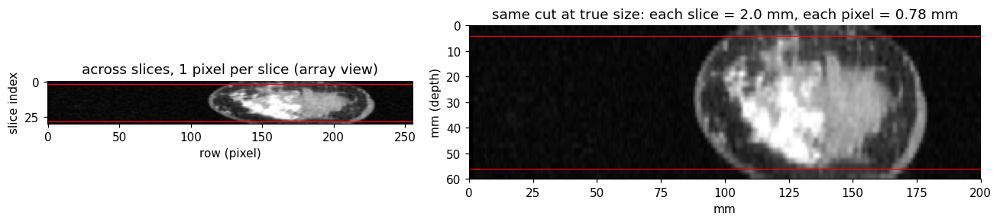

median voxel size per cohort (mm):


,xy_spacing,slice_thick,voxel_mm3,depth/width
cohort,,,,
ispy1,0.78,2.3,1.40,2.94
ispy2,0.68,2.0,0.93,2.93
duke,0.70,2.0,0.99,2.84


In [17]:
if HAVE_RAW:
    early = VOLS[USED[1]]
    zs = np.unique(np.linspace(0, early.shape[0] - 1, 8).round().astype(int))
    fig, axes = plt.subplots(1, len(zs), figsize=(2.1 * len(zs), 2.6))
    vmax = np.percentile(early, 99.5)
    for ax, z in zip(axes, zs):
        ax.imshow(early[z], cmap="gray", vmax=vmax); ax.axis("off")
        ax.set_title(f"slice {z}\n{z * TH:.0f} mm", fontsize=8, color="red" if Z0 <= z < Z1 else "black")
    fig.suptitle(f"early post-contrast volume {early.shape}: 8 of its {early.shape[0]} slices (red = contains tumour)")
    plt.tight_layout(); plt.show()

    cut = early[:, :, XC]                                   # (Z, H): one column through the tumour, across all slices
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
    axes[0].imshow(cut, cmap="gray", vmax=vmax, aspect=1)
    axes[0].set(title="across slices, 1 pixel per slice (array view)", xlabel="row (pixel)", ylabel="slice index")
    axes[1].imshow(cut, cmap="gray", vmax=vmax, extent=[0, cut.shape[1] * XY, cut.shape[0] * TH, 0])
    axes[1].set(title=f"same cut at true size: each slice = {TH:.1f} mm, each pixel = {XY:.2f} mm", xlabel="mm", ylabel="mm (depth)")
    for ax, s in [(axes[0], 1), (axes[1], TH)]:
        for z in (Z0, Z1):
            ax.axhline(z * s, color="red", lw=0.8)
    plt.tight_layout(); plt.show()

    vox = df.groupby("cohort")[["xy_spacing", "slice_thick"]].median().loc[COHORTS]
    vox["voxel_mm3"] = vox.xy_spacing ** 2 * vox.slice_thick
    vox["depth/width"] = vox.slice_thick / vox.xy_spacing
    print("median voxel size per cohort (mm):"); display(vox.round(2))

## C3. The image is just numbers

A 6×6 block of the raw array around the tumour centre, from the middle tumour slice, in each phase, next to a
block of background in the corner.
- Values are raw scanner units.
- The tumour is much brighter after contrast (early) than before (pre).

In [18]:
if HAVE_RAW:
    np.set_printoptions(linewidth=140, suppress=True)
    for k, name in zip(USED, ["pre", "early", "late"]):
        print(f"--- {name} (acquisition {k}), slice {ZM}, rows {YC - 3}-{YC + 2}, cols {XC - 3}-{XC + 2}:")
        print(np.rint(VOLS[k][ZM, YC - 3:YC + 3, XC - 3:XC + 3]).astype(int))
    print(f"--- background, early, slice {ZM}, rows 5-10, cols 5-10:")
    print(np.rint(VOLS[USED[1]][ZM, 5:11, 5:11]).astype(int))
    t = VOLS[USED[1]][ZM, YC - 3:YC + 3, XC - 3:XC + 3].mean() / max(VOLS[USED[0]][ZM, YC - 3:YC + 3, XC - 3:XC + 3].mean(), 1)
    print(f"tumour block: early / pre = {t:.2f}x brighter")

--- pre (acquisition 0), slice 15, rows 148-153, cols 98-103:
[[ 77  83  84  87  87  77]
 [ 83  83  78  84  90  75]
 [ 87  86  81  83  93  84]
 [ 87  90  90  85  91  90]
 [ 94  95  96  91  87  84]
 [101  93  94  93  87  84]]
--- early (acquisition 1), slice 15, rows 148-153, cols 98-103:
[[126 115 106 106 127 154]
 [124 117 107 108 134 163]
 [130 121 110 111 130 149]
 [141 126 105 102 115 133]
 [148 126 103 103 111 132]
 [147 121 118 124 130 144]]
--- late (acquisition 2), slice 15, rows 148-153, cols 98-103:
[[136 120 123 144 164 175]
 [134 120 126 141 159 169]
 [148 135 132 143 161 166]
 [163 142 125 136 154 157]
 [161 139 126 137 151 156]
 [164 150 154 161 171 163]]
--- background, early, slice 15, rows 5-10, cols 5-10:
[[ 6  7  3  3  7  7]
 [ 4  8  5  2  3  7]
 [ 7  9  6  3  4 13]
 [ 7  7  6  4  5  8]
 [ 5  7  6  7  6  4]
 [ 9  8  4  5  6  3]]
tumour block: early / pre = 1.43x brighter


## C4. The DCE time curve: why three phases

- Mean intensity inside the tumour (the mask, or the box for Duke) for **every** acquisition of this patient,
  next to the whole slice.
- The tumour rises after contrast, then washes out or plateaus.
- We keep three points: **pre** (R), **early** (G) and **late** (B), marked on the curve.

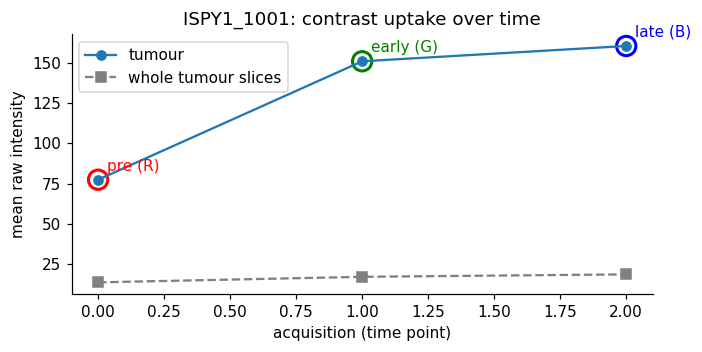

In [19]:
if HAVE_RAW:
    if MASK is not None and MASK[Z0:Z1].any():
        sel = np.zeros(MASK.shape, bool); sel[Z0:Z1] = MASK[Z0:Z1] > 0
    else:
        sel = np.zeros(VOLS[USED[0]].shape, bool); sel[Z0:Z1, BY0:BY1, BX0:BX1] = True
    tum = [VOLS[k][sel].mean() for k in ACQ]
    bg = [VOLS[k][Z0:Z1].mean() for k in ACQ]
    fig, ax = plt.subplots(figsize=(6.5, 3.3))
    ax.plot(ACQ, tum, "o-", label="tumour"); ax.plot(ACQ, bg, "s--", color="gray", label="whole tumour slices")
    for k, name, col in zip(USED, ["pre (R)", "early (G)", "late (B)"], ["red", "green", "blue"]):
        ax.scatter([k], [tum[ACQ.index(k)]], s=160, facecolors="none", edgecolors=col, linewidths=2)
        ax.annotate(name, (k, tum[ACQ.index(k)]), textcoords="offset points", xytext=(6, 6), color=col)
    ax.set(xlabel="acquisition (time point)", ylabel="mean raw intensity", title=f"{PID_}: contrast uptake over time")
    ax.legend(); plt.tight_layout(); plt.show()

## C5. Intensity normalisation: raw floats → uint8

- **One clip range per patient**, shared by the three phases: the 0.5th and 99.5th percentiles of all their
  voxels together.
- Below `lo` → 0, above `hi` → 255, linear in between.
- Sharing the range keeps the *difference* between channels, i.e. the contrast enhancement.
- Left: raw histograms with the clip lines. Right: the result.
- The last check confirms that our RGB, cropped the same way, is **identical** to the cache file the builder
  wrote.

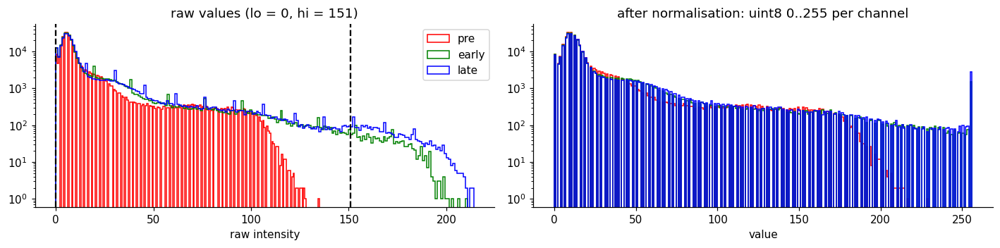

uint8 = round(clip((raw - 0.0) * 255 / (151.0 - 0.0), 0, 255))
tumour pixels as (R, G, B) triplets, slice 15, rows 150-152, cols 100-102:
[[[137 186 223]
  [140 187 241]
  [157 220 255]]

 [[152 177 211]
  [144 172 230]
  [154 194 255]]

 [[162 174 213]
  [154 174 231]
  [147 187 255]]]
our RGB, cropped like the cache, equals the builder's cache file: True


In [20]:
if HAVE_RAW:
    RGB, (lo, hi) = to_rgb_uint8(*[VOLS[k] for k in USED])        # (Z, 256, 256, 3) uint8
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.3))
    for k, name, col in zip(USED, ["pre", "early", "late"], ["red", "green", "blue"]):
        axes[0].hist(VOLS[k].ravel()[::7], bins=200, histtype="step", color=col, label=name, log=True)
    for v in (lo, hi):
        axes[0].axvline(v, color="k", ls="--")
    axes[0].set(title=f"raw values (lo = {lo:.0f}, hi = {hi:.0f})", xlabel="raw intensity"); axes[0].legend()
    for i, col in enumerate(["red", "green", "blue"]):
        axes[1].hist(RGB[..., i].ravel()[::7], bins=256, range=(0, 256), histtype="step", color=col, log=True)
    axes[1].set(title="after normalisation: uint8 0..255 per channel", xlabel="value")
    plt.tight_layout(); plt.show()
    print(f"uint8 = round(clip((raw - {lo:.1f}) * 255 / ({hi:.1f} - {lo:.1f}), 0, 255))")
    print(f"tumour pixels as (R, G, B) triplets, slice {ZM}, rows {YC - 1}-{YC + 1}, cols {XC - 1}-{XC + 1}:")
    print(RGB[ZM, YC - 1:YC + 2, XC - 1:XC + 2])
    s0 = int(CACHE["z_offset"])
    same = np.array_equal(CACHE["rgb"], RGB[s0:s0 + CACHE["rgb"].shape[0], cy0:cy0 + CACHE_SIZE, cx0:cx0 + CACHE_SIZE])
    print(f"our RGB, cropped like the cache, equals the builder's cache file: {same}")

## C6. Rebuilding the image: three grey slices → one colour image

Middle tumour slice, axes in **mm**.
- **R** = pre, **G** = early, **B** = late.
- **Green/yellow areas** brightened after contrast: tumour and vessels.
- The **subtraction** panel (early − pre) shows only the enhancement. We don't feed it to the model, but the
  model can compute it from R and G.
- Yellow box = tumour box; cyan = mask (I-SPY).

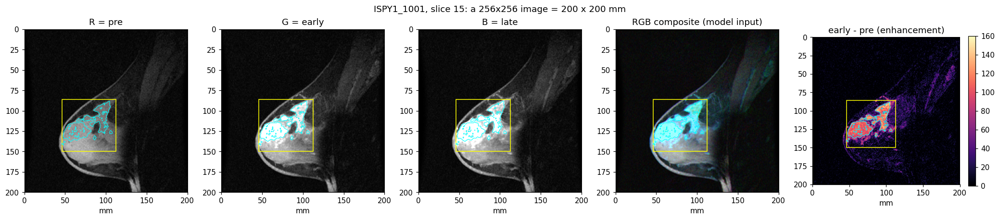

In [21]:
if HAVE_RAW:
    ext = [0, RGB.shape[2] * XY, RGB.shape[1] * XY, 0]
    fig, axes = plt.subplots(1, 5, figsize=(19, 4))
    for i, name in enumerate(["R = pre", "G = early", "B = late"]):
        axes[i].imshow(RGB[ZM, ..., i], cmap="gray", vmin=0, vmax=255, extent=ext); axes[i].set_title(name)
    axes[3].imshow(RGB[ZM], extent=ext); axes[3].set_title("RGB composite (model input)")
    sub = RGB[ZM, ..., 1].astype(int) - RGB[ZM, ..., 0].astype(int)
    im = axes[4].imshow(sub, cmap="magma", vmin=0, vmax=max(sub.max(), 1), extent=ext); axes[4].set_title("early - pre (enhancement)")
    for ax in axes:
        ax.add_patch(plt.Rectangle((BX0 * XY, BY0 * XY), (BX1 - BX0) * XY, (BY1 - BY0) * XY, fill=False, ec="yellow", lw=1))
        if MASK is not None and MASK[ZM].any():
            ax.contour((np.arange(MASK.shape[2]) + 0.5) * XY, (np.arange(MASK.shape[1]) + 0.5) * XY, MASK[ZM], levels=[0.5], colors="cyan", linewidths=0.7)
        ax.set_xlabel("mm")
    plt.colorbar(im, ax=axes[4], fraction=0.046)
    fig.suptitle(f"{PID_}, slice {ZM}: a {RGB.shape[1]}x{RGB.shape[2]} image = {RGB.shape[1] * XY:.0f} x {RGB.shape[2] * XY:.0f} mm")
    plt.tight_layout(); plt.show()

## C7. Which slices the model uses

- The cache keeps the tumour slices plus 2 margin slices on each side (grey titles). The model uses only the
  tumour slices (black titles).
- Each step, a patient is a **bag** of slices:
  - **training:** 8 random tumour slices, redrawn every epoch;
  - **evaluation:** 16 evenly spaced ones.

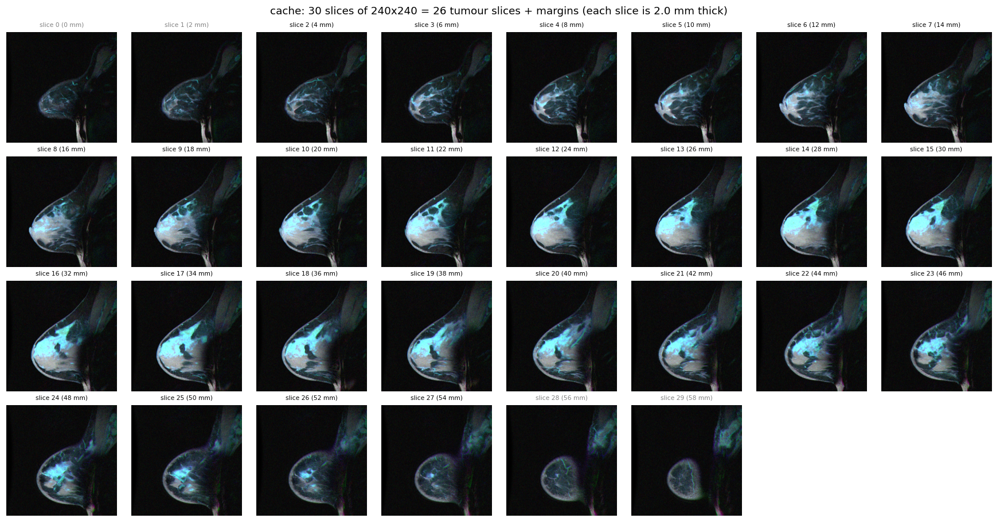

26 tumour slices -> training bag (one epoch): [0, 1, 5, 7, 10, 12, 16, 25] | evaluation bag: [0, 2, 3, 5, 7, 8, 10, 12, 13, 15, 17, 18, 20, 22, 23, 25]


In [22]:
if HAVE_RAW:
    C, t0, t1 = CACHE["rgb"], int(CACHE["t0"]), int(CACHE["t1"])
    n = min(len(C), 32); cols = 8; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2.1 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i in range(n):
        z = int(CACHE["z_offset"]) + i
        ax = axes.ravel()[i]; ax.imshow(C[i])
        ax.set_title(f"slice {z} ({z * TH:.0f} mm)", fontsize=7, color="black" if t0 <= i < t1 else "gray")
    fig.suptitle(f"cache: {len(C)} slices of 240x240 = {t1 - t0} tumour slices + margins (each slice is {TH:.1f} mm thick)")
    plt.tight_layout(); plt.show()

    s = t1 - t0
    rng = np.random.default_rng(0)
    train_bag = np.sort(rng.choice(s, 8, replace=s < 8))                      # same rule as PatientBags._pick
    eval_bag = np.arange(s) if s <= 16 else np.unique(np.linspace(0, s - 1, 16).round().astype(int))
    print(f"{s} tumour slices -> training bag (one epoch): {train_bag.tolist()} | evaluation bag: {eval_bag.tolist()}")

## C8. 256 → 240 → 224, and what that means in mm

1. **256 → 240:**
   - The cache cuts 240×240 around the tumour centre (green), shifted inward if needed.
2. **240 → 224:**
   - The model gets the centre 224×224 (magenta).
   - In training, a random flip, rotation, scale and shift is applied first.
   - **224 is the size the ViT was pretrained on.**
3. **No resizing at any step.** So the crop's size in mm is **224 × pixel size**:
   - 224 × 0.39 mm ≈ **87 mm** on a fine-resolution scan;
   - 224 × 0.70 mm ≈ **157 mm** on a typical one.

The last figure shows 224-px crops from different patients **at true physical scale**: the same 224 pixels
cover very different amounts of breast.

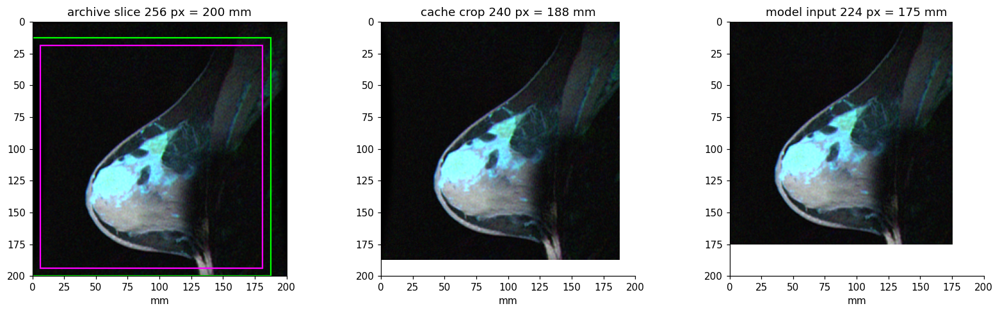

what a 224-px crop covers, in mm (from each scan's pixel size):


,min,50%,max
cohort,,,
ispy1,88.0,175.0,263.0
ispy2,70.0,153.0,315.0
duke,114.0,157.0,280.0


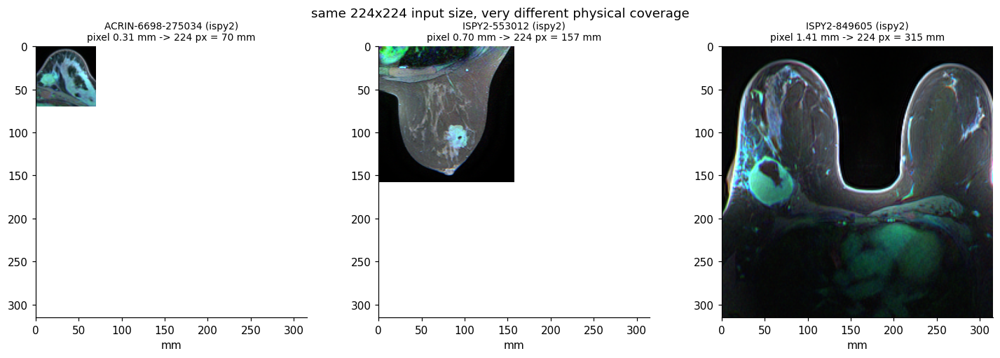

In [23]:
if HAVE_RAW:
    o = (CACHE_SIZE - INPUT_SIZE) // 2
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    axes[0].imshow(RGB[ZM], extent=[0, RGB.shape[2] * XY, RGB.shape[1] * XY, 0])
    axes[0].add_patch(plt.Rectangle((cx0 * XY, cy0 * XY), CACHE_SIZE * XY, CACHE_SIZE * XY, fill=False, ec="lime", lw=1.5))
    axes[0].add_patch(plt.Rectangle(((cx0 + o) * XY, (cy0 + o) * XY), INPUT_SIZE * XY, INPUT_SIZE * XY, fill=False, ec="magenta", lw=1.5))
    axes[0].set(title=f"archive slice {RGB.shape[1]} px = {RGB.shape[1] * XY:.0f} mm", xlabel="mm")
    c240 = CACHE["rgb"][ZM - int(CACHE["z_offset"])]
    axes[1].imshow(c240, extent=[0, CACHE_SIZE * XY, CACHE_SIZE * XY, 0]); axes[1].set(title=f"cache crop 240 px = {CACHE_SIZE * XY:.0f} mm", xlabel="mm")
    axes[2].imshow(c240[o:o + INPUT_SIZE, o:o + INPUT_SIZE], extent=[0, INPUT_SIZE * XY, INPUT_SIZE * XY, 0])
    axes[2].set(title=f"model input 224 px = {INPUT_SIZE * XY:.0f} mm", xlabel="mm")
    for ax in axes[1:]:
        ax.set_xlim(0, RGB.shape[2] * XY); ax.set_ylim(RGB.shape[1] * XY, 0)
    plt.tight_layout(); plt.show()

fov = df.assign(fov224_mm=224 * df.xy_spacing).groupby("cohort").fov224_mm.describe()[["min", "50%", "max"]].loc[COHORTS]
print("what a 224-px crop covers, in mm (from each scan's pixel size):"); display(fov.round(0))

if HAVE_CACHE:
    pool = train[train.cohort.isin(list(CACHES))]
    pool = pool[[(CACHES[c] / f"{p}.npz").exists() for p, c in zip(pool.pid, pool.cohort)]]
    if len(pool):
        picks = pool.sort_values("xy_spacing").iloc[[0, len(pool) // 2, -1]].drop_duplicates("pid")
        big = 224 * picks.xy_spacing.max()
        fig, axes = plt.subplots(1, len(picks), figsize=(4.5 * len(picks), 4.5), squeeze=False)
        for ax, (_, p) in zip(axes[0], picks.iterrows()):
            d = np.load(CACHES[p.cohort] / f"{p.pid}.npz")
            k = (int(d["t0"]) + int(d["t1"])) // 2
            ax.imshow(d["rgb"][k, 8:232, 8:232], extent=[0, 224 * p.xy_spacing, 224 * p.xy_spacing, 0])
            ax.set_xlim(0, big); ax.set_ylim(big, 0)
            ax.set_title(f"{p.pid} ({p.cohort})\npixel {p.xy_spacing:.2f} mm -> 224 px = {224 * p.xy_spacing:.0f} mm", fontsize=9)
            ax.set_xlabel("mm")
        fig.suptitle("same 224x224 input size, very different physical coverage")
        plt.tight_layout(); plt.show()

## C9. The exact tensor given to the ViT

1. Take the patient's evaluation bag (up to 16 tumour slices), shape **(1, K, 3, 240, 240) uint8**: batch,
   slices, channels, rows, columns.
2. `eval_transform` crops the centre 224, divides by 255 and subtracts the ImageNet mean / divides by the
   ImageNet SD per channel, giving **(1, K, 3, 224, 224) float32**, roughly zero-mean.
3. The ViT cuts each slice into **14 × 14 = 196 patches** of 16×16 px (each about 16 × pixel size mm wide),
   adds a [CLS] token (197 tokens), and returns one 768-number vector per slice.
4. B3 averages the K slice predictions; F2 passes the K slice vectors to the fusion transformer.

The last row shows **training-time augmentation** of the same slice: four random draws.

bag from the cache : (1, 16, 3, 240, 240) torch.uint8 values 0 - 255
tensor into the ViT: (1, 16, 3, 224, 224) torch.float32 values -2.12 - 2.64
per-channel mean after /255     : [0.098 0.123 0.133] (ImageNet mean (0.485, 0.456, 0.406) )
per-channel mean after normalise: [-1.652 -1.439 -1.158] | SD: [0.603 0.841 0.913]
patches per slice: 196 (+1 [CLS] = 197 tokens), each 16 px = 12.5 mm wide


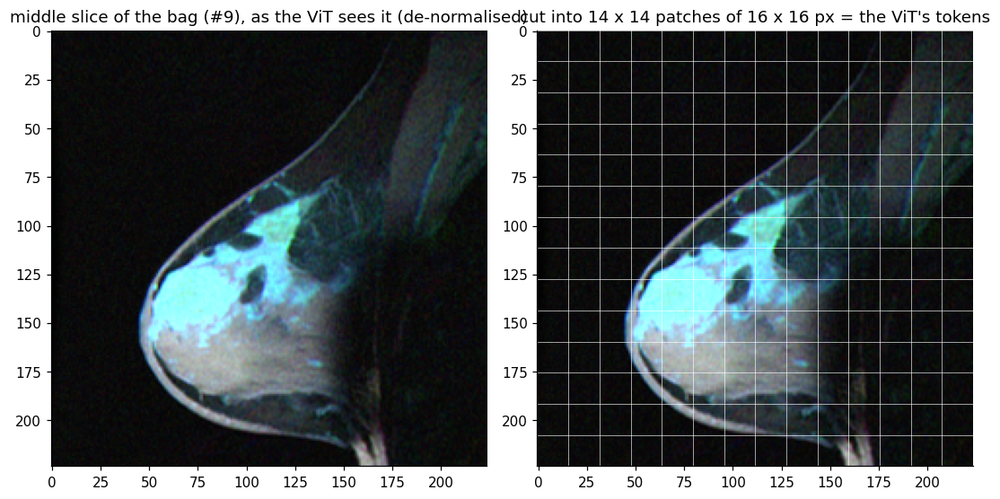

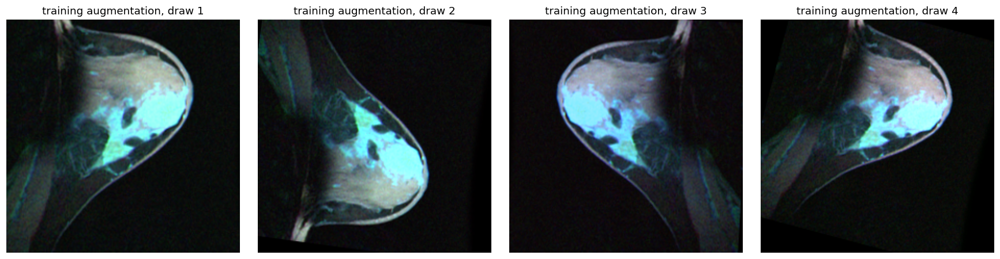

In [24]:
if HAVE_RAW:
    import torch
    from src.data.transforms import eval_transform, train_transform
    from src.models.vit_encoder import IMAGENET_MEAN, IMAGENET_STD
    tum = CACHE["rgb"][int(CACHE["t0"]):int(CACHE["t1"])]
    x = torch.from_numpy(tum[eval_bag]).permute(0, 3, 1, 2)[None]        # (1, K, 3, 240, 240) uint8
    xe = eval_transform(x, IMAGENET_MEAN, IMAGENET_STD)                    # (1, K, 3, 224, 224) float32
    print("bag from the cache :", tuple(x.shape), x.dtype, "values", int(x.min()), "-", int(x.max()))
    print("tensor into the ViT:", tuple(xe.shape), xe.dtype, "values %.2f - %.2f" % (xe.min(), xe.max()))
    print("per-channel mean after /255     :", np.round(x.float().div(255).mean(dim=(0, 1, 3, 4)).numpy(), 3), "(ImageNet mean", IMAGENET_MEAN, ")")
    print("per-channel mean after normalise:", np.round(xe.mean(dim=(0, 1, 3, 4)).numpy(), 3),
          "| SD:", np.round(xe.std(dim=(0, 1, 3, 4)).numpy(), 3))
    print(f"patches per slice: {(224 // 16) ** 2} (+1 [CLS] = 197 tokens), each 16 px = {16 * XY:.1f} mm wide")

    m, sd = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
    show = lambda t: (t * sd + m).clamp(0, 1).permute(1, 2, 0).numpy()
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    mid = xe.shape[1] // 2
    axes[0].imshow(show(xe[0, mid])); axes[0].set_title(f"middle slice of the bag (#{mid + 1}), as the ViT sees it (de-normalised)")
    axes[1].imshow(show(xe[0, mid]))
    for g in range(0, 225, 16):
        axes[1].axhline(g - 0.5, color="w", lw=0.4); axes[1].axvline(g - 0.5, color="w", lw=0.4)
    axes[1].set_title("cut into 14 x 14 patches of 16 x 16 px = the ViT's tokens")
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for i, ax in enumerate(axes):
        xa = train_transform(x[:, mid:mid + 1], IMAGENET_MEAN, IMAGENET_STD, generator=torch.Generator().manual_seed(i))
        ax.imshow(show(xa[0, 0])); ax.set_title(f"training augmentation, draw {i + 1}"); ax.axis("off")
    plt.tight_layout(); plt.show()